:::{danger} Ejercicio sin validar: no usar para tomar decisiones
Este cuaderno **no ha sido validado por una persona experta** en modelación de tsunamis. Es un ejercicio de reproducibilidad y de aprendizaje. Sus resultados **no deben usarse para tomar decisiones** de gestión del riesgo, ordenamiento territorial, diseño de obras, planes de evacuación ni alertas.

Falta, como mínimo: la revisión por una persona experta; la distribución de deslizamiento real del evento (la geometría de la falla es un supuesto); la validación contra observaciones de 1979 que se contradicen entre fuentes (véase el cuaderno 3); y un modelo no lineal con cálculo de inundación.
:::

# Cuaderno 1: Batimetría y topografía

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/scr-ungrd/cuadernos-reproducibles-crc002/blob/main/notebooks/01-bathymetry.ipynb)

Prepara el modelo digital de elevación (DEM) del dominio de simulación del tsunami de Tumaco de 1979:
**0,2° S–4,2° N y 81,2°–76,9° O** (unos 480 × 480 km), que cubre Tumaco, Esmeraldas (Ecuador) y Buenaventura
y deja la fuente sísmica lejos de los bordes. **Runtime:** CPU, menos de 1 minuto.

**Fuente de los datos.** El DEM sale del servicio de mosaico global de NOAA/NCEI
(`DEM_mosaics/DEM_global_mosaic`), pedido a 15 arco-segundos (~460 m). Es un *mosaico* de modelos de distinta resolución y
procedencia, por lo que **no es GEBCO ni ETOPO 2022 puros** (la versión 1 de este cuaderno los nombraba; el enlace de
descarga de GEBCO que usaba ya no responde). Una copia del recorte está en `data/dem_tumaco_noaa_15s.tif` para que el cuaderno no
dependa del servidor.

In [1]:
import sys, subprocess, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'rasterio', 'pyproj'], check=True)
import rasterio
from rasterio.crs import CRS
from pyproj import Transformer

WORK = Path('/content') if IN_COLAB else Path('.')
OUT = WORK / 'output'
OUT.mkdir(exist_ok=True)
RAW = 'https://raw.githubusercontent.com/scr-ungrd/cuadernos-reproducibles-crc002/main/data/'

def datos(nombre):
    """Ruta de un archivo de data/: local (../data) o descargado del repositorio (Colab)."""
    for base in (Path('../data'), Path('data'), WORK / 'data'):
        if (base / nombre).exists():
            return base / nombre
    import requests
    destino = WORK / 'data'
    destino.mkdir(exist_ok=True)
    r = requests.get(RAW + nombre, timeout=120)
    r.raise_for_status()
    (destino / nombre).write_bytes(r.content)
    return destino / nombre

# Epicentro del 12-dic-1979 (1,584° N, 79,386° O: tabla 1 de Herd et al., 1981, hipocentro del NEIS)
EPI = (-79.386, 1.584)                       # (lon, lat)
CRS_UTM = CRS.from_epsg(32617)               # UTM 17N, meridiano central 81° O (error de escala < 0,2 % en el dominio)
TR = Transformer.from_crs(4326, 32617, always_xy=True)
G = 9.81

def ejes_lonlat(ax, paso=1):
    """Marcas de longitud y latitud sobre un mapa en coordenadas UTM (km); oeste a la izquierda, norte arriba."""
    lons = np.arange(-81, -76.5, paso); lats = np.arange(0, 4.5, paso)
    xl, yl = ax.get_xlim(), ax.get_ylim()
    ax.set_xticks([TR.transform(l, 2.0)[0] / 1e3 for l in lons]); ax.set_xticklabels([f'{abs(l):g}°O' for l in lons])
    ax.set_yticks([TR.transform(-79.0, l)[1] / 1e3 for l in lats]); ax.set_yticklabels([f'{l:g}°N' for l in lats])
    ax.set_xlim(xl); ax.set_ylim(yl)
    ax.set_xlabel('Longitud'); ax.set_ylabel('Latitud')

## 1. Recorte geográfico del DEM

In [2]:
BBOX = (-81.2, -0.2, -76.9, 4.2)     # lon_min, lat_min, lon_max, lat_max
NC, NR = 1032, 1056                  # 15 arco-segundos

def dem_geografico():
    """Usa la copia del repositorio; si no está, pide el recorte al servicio NOAA/NCEI."""
    try:
        return datos('dem_tumaco_noaa_15s.tif')
    except Exception as e:
        print('Copia no disponible (', type(e).__name__, '); descargando de NOAA/NCEI...')
        import requests
        url = ('https://gis.ngdc.noaa.gov/arcgis/rest/services/DEM_mosaics/DEM_global_mosaic/ImageServer/exportImage'
               f'?bbox={BBOX[0]},{BBOX[1]},{BBOX[2]},{BBOX[3]}&bboxSR=4326&size={NC},{NR}&imageSR=4326'
               '&format=tiff&pixelType=F32&f=image')
        r = requests.get(url, timeout=180); r.raise_for_status()
        destino = WORK / 'data'; destino.mkdir(exist_ok=True)
        (destino / 'dem_tumaco_noaa_15s.tif').write_bytes(r.content)
        return destino / 'dem_tumaco_noaa_15s.tif'

ruta_geo = dem_geografico()
with rasterio.open(ruta_geo) as s:
    z = s.read(1); b = s.bounds
    # Comprobaciones: un DEM vacío, sintético o mal recortado no debe pasar en silencio
    assert np.isfinite(z).all(), 'DEM con valores no finitos'
    assert z.min() < -4000 and z.max() > 3000, 'rango de elevaciones inesperado'
    assert abs(b.left - BBOX[0]) < 0.01 and abs(b.top - BBOX[3]) < 0.01, 'recorte distinto al esperado'
    print(f'DEM geográfico {z.shape[1]}×{z.shape[0]} | elev. {z.min():.0f} a {z.max():.0f} m | océano {100*(z<0).mean():.0f} % del área')
    for nombre, (lon, lat) in {'Tumaco': (-78.76, 1.82), 'Epicentro': EPI}.items():
        r_, c_ = s.index(lon, lat); print(f'  {nombre}: {z[r_, c_]:.0f} m')

DEM geográfico 1032×1056 | elev. -5183 a 5615 m | océano 59 % del área
  Tumaco: 4 m
  Epicentro: -825 m


## 2. Reproyección a UTM 17N (450 m)

La malla es regular, con el **norte arriba y el oeste a la izquierda** (fila 0 = norte, columna 0 = oeste). La versión 1 invertía el
eje X al guardar el DEM y eso espejaba los mapas; aquí no se invierte nada.

In [3]:
from rasterio.warp import calculate_default_transform, reproject, Resampling

def a_utm(ruta, dx=450.0):
    """Reproyecta el DEM a UTM 17N con celdas de `dx` m (interpolación bilineal). Devuelve la malla (m, NaN sin dato) y su transformación afín."""
    with rasterio.open(ruta) as src:
        tf, w, h = calculate_default_transform(src.crs, CRS_UTM, src.width, src.height, *src.bounds, resolution=dx)
        arr = np.full((h, w), np.nan, 'float32')
        reproject(rasterio.band(src, 1), arr, src_transform=src.transform, src_crs=src.crs,
                  dst_transform=tf, dst_crs=CRS_UTM, resampling=Resampling.bilinear, dst_nodata=np.nan)
    return arr, tf

dem, tf = a_utm(ruta_geo, 450.0)
print(f'UTM 17N: {dem.shape[1]}×{dem.shape[0]} celdas de 450 m | {dem.shape[1]*0.45:.0f} × {dem.shape[0]*0.45:.0f} km')
print(f'Celdas sin dato (bordes de la reproyección): {np.isnan(dem).sum()} ({100*np.isnan(dem).mean():.2f} %); se tratan como tierra')

with rasterio.open(OUT / 'dem_utm17_450m.tif', 'w', driver='GTiff', height=dem.shape[0], width=dem.shape[1], count=1,
                   dtype='float32', crs=CRS_UTM, transform=tf, nodata=np.nan) as dst:
    dst.write(dem, 1)

# Orientación: el punto de mayor profundidad debe estar al oeste de la costa, no al este
ny, nx = dem.shape
x_oc = np.nanmean(np.where(dem < -3000)[1]); x_tierra = np.nanmean(np.where(dem > 500)[1])
assert x_oc < x_tierra, 'orientación invertida: el océano profundo debe quedar a la izquierda (oeste)'
print('✓ Orientación correcta: océano profundo al oeste, relieve al este')

UTM 17N: 1065×1084 celdas de 450 m | 479 × 488 km
Celdas sin dato (bordes de la reproyección): 4665 (0.40 %); se tratan como tierra
✓ Orientación correcta: océano profundo al oeste, relieve al este


## 3. Vista general con las estaciones de 1979 y el epicentro

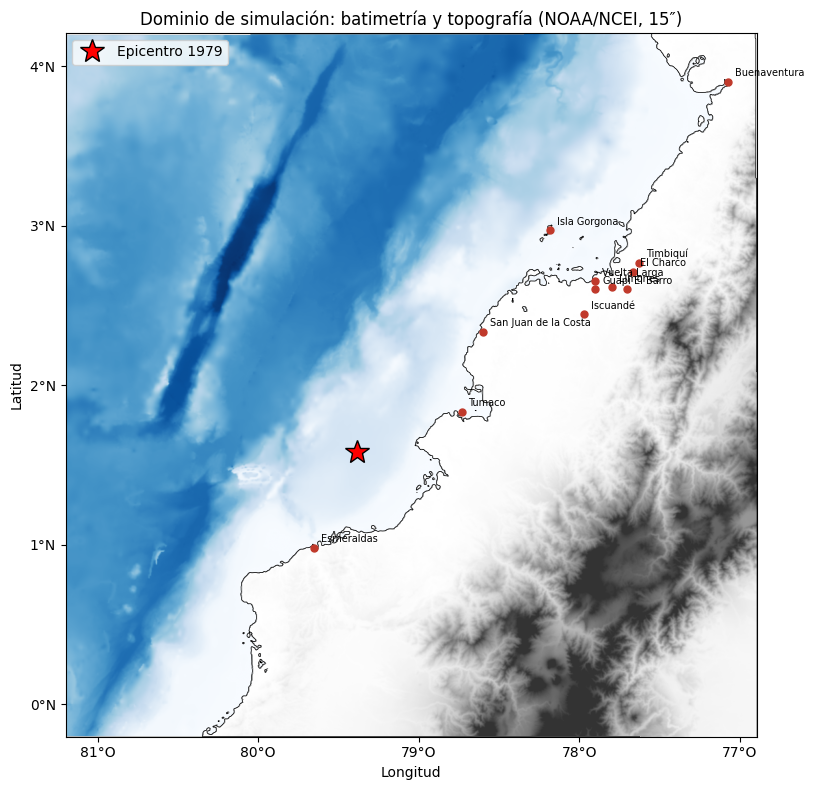

Estaciones fuera del dominio: []


In [4]:
obs = pd.read_csv(datos('observaciones_1979.csv'))
ext = [tf.c / 1e3, (tf.c + tf.a * nx) / 1e3, (tf.f + tf.e * ny) / 1e3, tf.f / 1e3]
fig, ax = plt.subplots(figsize=(8.5, 8))
ax.imshow(np.where(dem < 0, dem, np.nan), cmap='Blues_r', vmin=-5000, vmax=0, extent=ext)
ax.imshow(np.where(dem >= 0, dem, np.nan), cmap='Greys', vmin=0, vmax=3500, extent=ext, alpha=.8)
xc = np.linspace(ext[0], ext[1], nx); yc = np.linspace(ext[3], ext[2], ny)
ax.contour(xc, yc, np.nan_to_num(dem), levels=[0], colors='k', linewidths=.5)
for _, r in obs.iterrows():
    x, y = TR.transform(r.lon, r.lat)
    ax.plot(x / 1e3, y / 1e3, 'o', c='#c0392b', ms=5)
    ax.annotate(r.estacion, (x / 1e3, y / 1e3), textcoords='offset points', xytext=(5, 4), fontsize=7)
ex, ey = TR.transform(*EPI)
ax.plot(ex / 1e3, ey / 1e3, '*', c='red', mec='k', ms=18, label='Epicentro 1979')
ax.legend(loc='upper left'); ejes_lonlat(ax)
ax.set_title('Dominio de simulación: batimetría y topografía (NOAA/NCEI, 15″)')
plt.tight_layout(); plt.savefig(WORK / 'dem_overview.png', dpi=130); plt.show()
print('Estaciones fuera del dominio:', [r.estacion for _, r in obs.iterrows()
      if not (BBOX[0] <= r.lon <= BBOX[2] and BBOX[1] <= r.lat <= BBOX[3])])